# Component 4 — Model Evaluation Dashboard

This notebook visualizes the saved evaluation evidence for the scaffold-action and targeted-practice models, then demonstrates how BKT mastery and Rasch/IRT ability change over time.

> **Research boundary:** the two selection models were trained and tested with deterministic synthetic learners. These results demonstrate software/model functionality; they are **not evidence of learning efficacy with real children**.

In [1]:
from pathlib import Path
import json
import math
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit

def find_service_root():
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        direct = parent
        nested = parent / 'app' / 'backend' / 'adaptive-tutoring-v1'
        for candidate in (direct, nested):
            if (candidate / 'models' / 'c4_action_outcome_v1.json').exists():
                return candidate
    raise FileNotFoundError('Run this notebook from the repository or adaptive-tutoring-v1 directory.')

SERVICE_ROOT = find_service_root()
if str(SERVICE_ROOT) not in sys.path:
    sys.path.insert(0, str(SERVICE_ROOT))

from research.generate_synthetic_action_data import FEATURES as ACTION_FEATURES, generate_rows
from research.generate_synthetic_practice_data import FEATURES as PRACTICE_FEATURES, rows as generate_practice_rows
from services.bkt_engine import BKTEngine
from services.irt_engine import IRTEngine

action_artifact = json.loads((SERVICE_ROOT / 'models' / 'c4_action_outcome_v1.json').read_text())
practice_artifact = json.loads((SERVICE_ROOT / 'models' / 'c4_practice_selector_v1.json').read_text())

SEED = 26031
BLUE, GREEN, AMBER, RED, NAVY = '#2787e6', '#18a558', '#f2a93b', '#ef4f5f', '#12356b'
sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({'figure.figsize': (11, 6), 'axes.titleweight': 'bold', 'axes.titlesize': 18})
print('Service root:', SERVICE_ROOT)

Service root: /Users/isara/4Y_2S/RP/R26-SE-031/app/backend/adaptive-tutoring-v1


## 1. Saved held-out results

In [2]:
action_summary = action_artifact['held_out_model_comparison']['logistic_regression']
practice_summary = practice_artifact['held_out_group_evaluation']
summary = pd.DataFrame([
    {
        'Model': 'Scaffold action — Logistic Regression',
        'Accuracy': action_summary['accuracy'],
        'ROC-AUC': action_summary['roc_auc'],
        'Brier score': action_summary['brier_score'],
        'Log loss': action_summary['log_loss'],
        'Validation': action_artifact['validation_status'],
    },
    {
        'Model': 'Targeted practice — Logistic Regression',
        'Accuracy': practice_summary['accuracy'],
        'ROC-AUC': practice_summary['roc_auc'],
        'Brier score': practice_summary['brier_score'],
        'Log loss': np.nan,
        'Validation': practice_artifact['validation_status'],
    },
])
display(summary.style.format({'Accuracy': '{:.2%}', 'ROC-AUC': '{:.3f}', 'Brier score': '{:.3f}', 'Log loss': '{:.3f}'})
        .background_gradient(subset=['Accuracy', 'ROC-AUC'], cmap='Blues'))
print('Action model:', action_artifact['model_version'])
print('Practice model:', practice_artifact['model_version'])

,Model,Accuracy,ROC-AUC,Brier score,Log loss,Validation
0,Scaffold action — Logistic Regression,88.86%,0.708,0.092,0.322,synthetic_only
1,Targeted practice — Logistic Regression,80.32%,0.710,0.145,nan,synthetic_only


Action model: c4-action-outcome-synthetic-v2
Practice model: c4-practice-selector-synthetic-v1


## 2. Learner-independent 75/25 evaluation split

Rows are regenerated with the artifact seed. Learner IDs—not individual rows—are split, so the same simulated learner cannot occur in both sets.

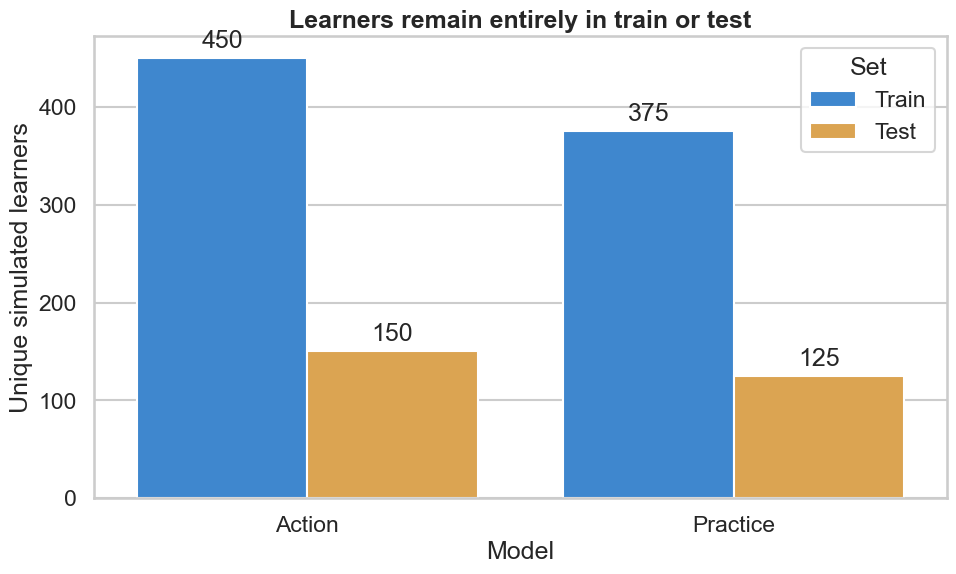

,Model,Set,Learners
0,Action,Train,450
1,Action,Test,150
2,Practice,Train,375
3,Practice,Test,125


In [3]:
action_df = pd.DataFrame(generate_rows(SEED, learners=600, interactions=24))
practice_df = pd.DataFrame(generate_practice_rows(SEED, learners=500, decisions=20))

action_x = action_df[list(ACTION_FEATURES)].to_numpy(float)
action_y = action_df['next_independent_success'].to_numpy(int)
action_groups = action_df['student_id'].to_numpy()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
action_train_idx, action_test_idx = next(splitter.split(action_x, action_y, action_groups))

practice_learners = sorted(practice_df['student_id'].unique())
random.Random(SEED).shuffle(practice_learners)
practice_cut = int(len(practice_learners) * 0.75)
practice_train_ids = set(practice_learners[:practice_cut])
practice_test_mask = ~practice_df['student_id'].isin(practice_train_ids)

split_counts = pd.DataFrame({
    'Model': ['Action', 'Action', 'Practice', 'Practice'],
    'Set': ['Train', 'Test', 'Train', 'Test'],
    'Learners': [
        action_df.iloc[action_train_idx]['student_id'].nunique(),
        action_df.iloc[action_test_idx]['student_id'].nunique(),
        len(practice_train_ids),
        len(practice_learners) - len(practice_train_ids),
    ],
})
ax = sns.barplot(data=split_counts, x='Model', y='Learners', hue='Set', palette=[BLUE, AMBER])
ax.set_title('Learners remain entirely in train or test')
ax.bar_label(ax.containers[0], padding=4)
ax.bar_label(ax.containers[1], padding=4)
ax.set_ylabel('Unique simulated learners')
plt.show()
display(split_counts)

## 3. Scaffold action model — evidence by action

Accuracy alone can look high when outcomes are imbalanced, so ROC-AUC and Brier score are shown beside it. Higher accuracy/AUC is better; lower Brier score is better.

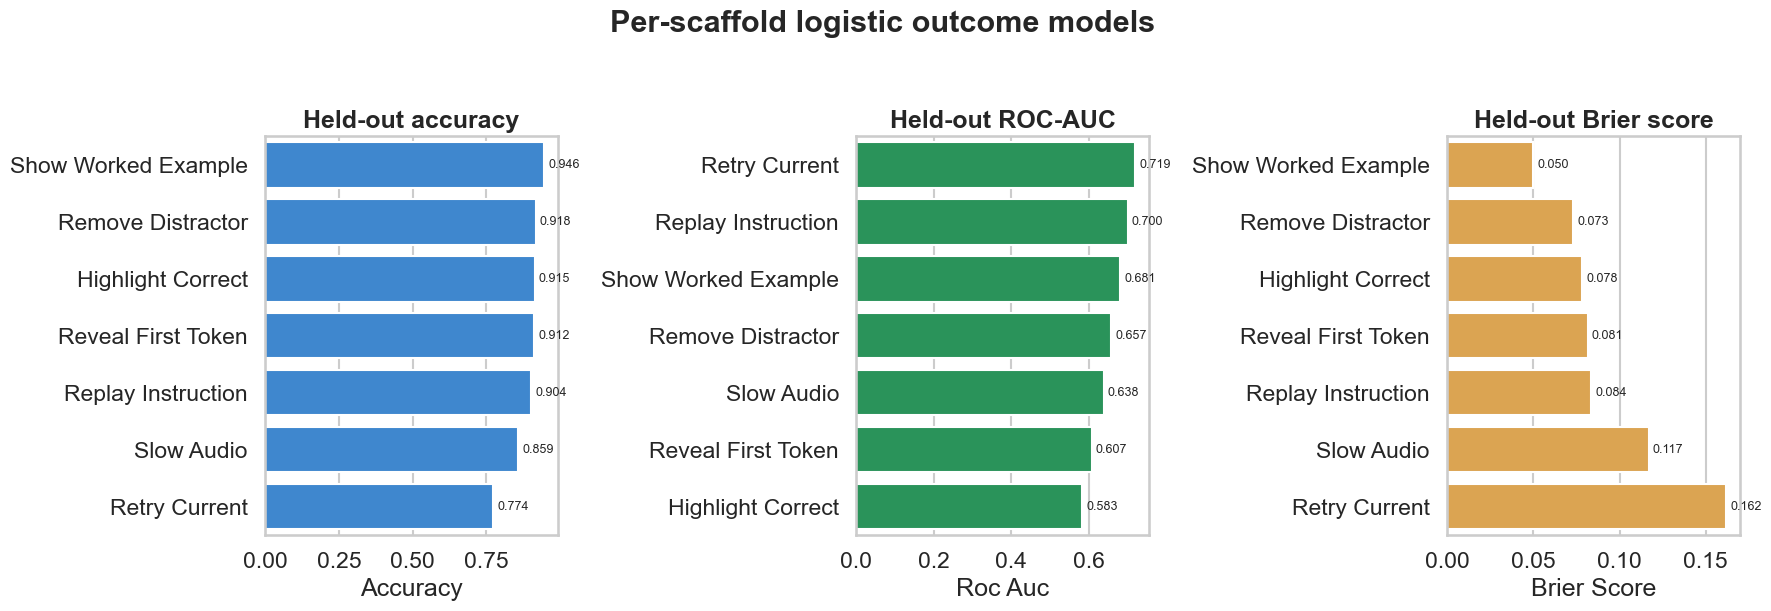

In [4]:
action_metrics = pd.DataFrame(action_artifact['held_out_group_evaluation']).T.reset_index(names='Action')
action_metrics['Action'] = action_metrics['Action'].str.replace('SCAFFOLD_', '', regex=False).str.replace('_', ' ').str.title()
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, metric, title, color in zip(
    axes, ['accuracy', 'roc_auc', 'brier_score'],
    ['Held-out accuracy', 'Held-out ROC-AUC', 'Held-out Brier score'],
    [BLUE, GREEN, AMBER],
):
    ordered = action_metrics.sort_values(metric, ascending=(metric == 'brier_score'))
    sns.barplot(data=ordered, y='Action', x=metric, ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel(metric.replace('_', ' ').title())
    ax.set_ylabel('')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)
plt.suptitle('Per-scaffold logistic outcome models', fontsize=22, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

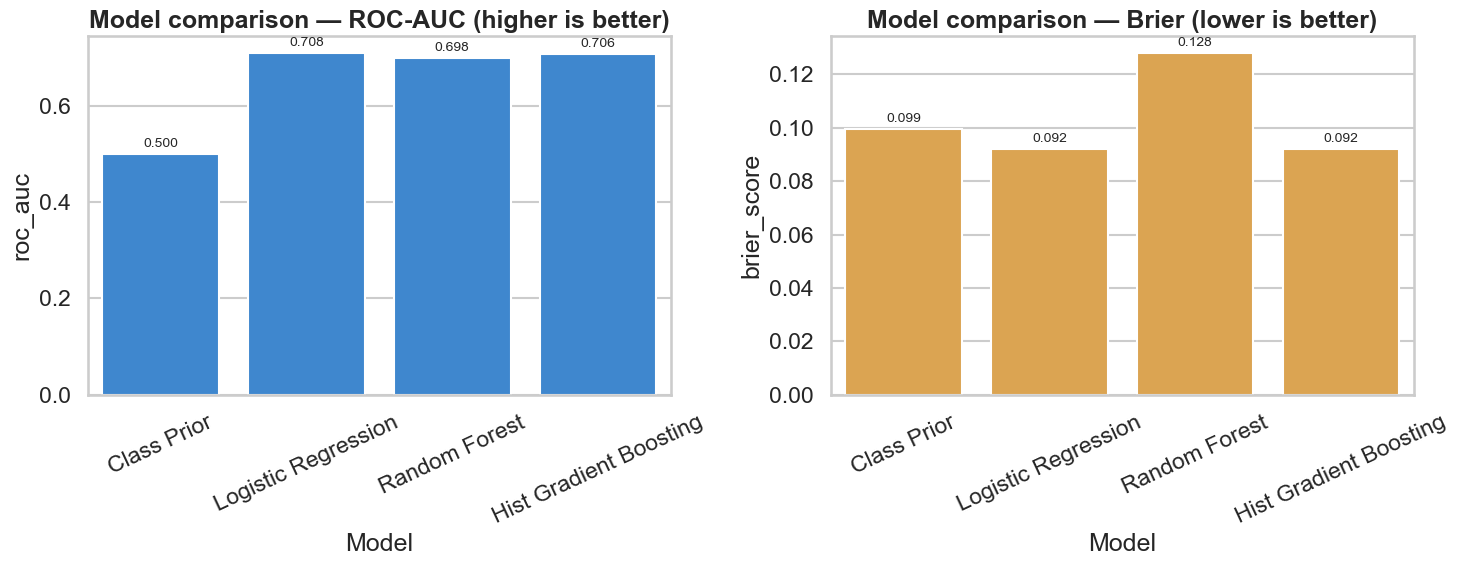

,Model,accuracy,brier_score,log_loss,roc_auc
0,Class Prior,0.888,0.099,0.351,0.500
1,Logistic Regression,0.889,0.092,0.322,0.708
2,Random Forest,0.852,0.128,0.419,0.698
3,Hist Gradient Boosting,0.889,0.092,0.321,0.706


In [5]:
comparison = pd.DataFrame(action_artifact['held_out_model_comparison']).T.reset_index(names='Model')
comparison['Model'] = comparison['Model'].str.replace('_', ' ').str.title()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=comparison, x='Model', y='roc_auc', ax=axes[0], color=BLUE)
sns.barplot(data=comparison, x='Model', y='brier_score', ax=axes[1], color=AMBER)
axes[0].set_title('Model comparison — ROC-AUC (higher is better)')
axes[1].set_title('Model comparison — Brier (lower is better)')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10)
plt.tight_layout()
plt.show()
display(comparison.style.format({column: '{:.3f}' for column in ['accuracy', 'brier_score', 'log_loss', 'roc_auc']}))

## 4. Targeted-practice selector — held-out evidence

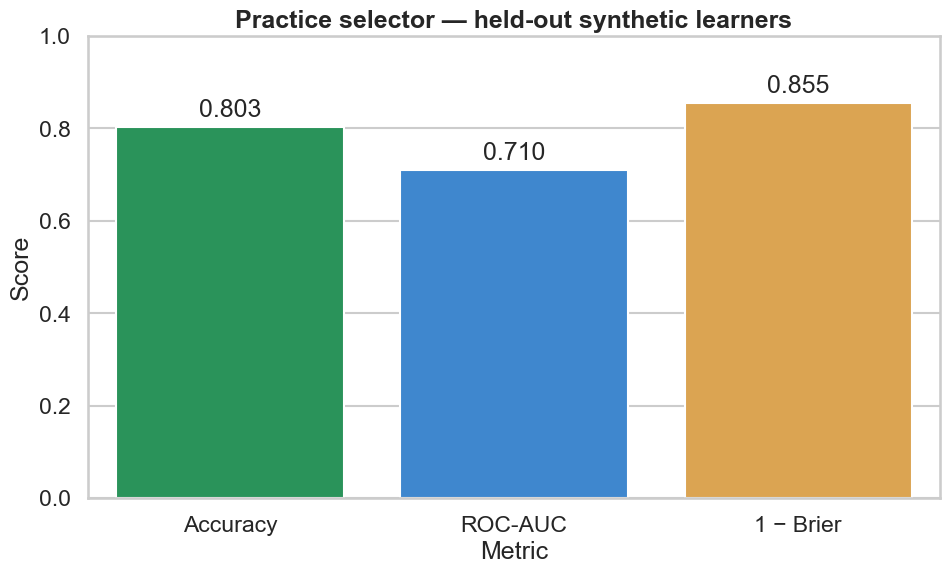

Train learners: 375 | Test learners: 125 | Test rows: 2500
Actual Brier score (lower is better): 0.145


In [6]:
practice_plot = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC-AUC', '1 − Brier'],
    'Value': [practice_summary['accuracy'], practice_summary['roc_auc'], 1 - practice_summary['brier_score']],
})
ax = sns.barplot(data=practice_plot, x='Metric', y='Value', hue='Metric', legend=False, palette=[GREEN, BLUE, AMBER])
ax.set_ylim(0, 1)
ax.set_title('Practice selector — held-out synthetic learners')
ax.set_ylabel('Score')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=4)
plt.show()
print(f"Train learners: {practice_summary['train_learners']} | Test learners: {practice_summary['test_learners']} | Test rows: {practice_summary['test_rows']}")
print(f"Actual Brier score (lower is better): {practice_summary['brier_score']:.3f}")

## 5. Explainability — learned standardized coefficients

Positive coefficients increase predicted independent success; negative coefficients decrease it. Because inputs were standardized, magnitudes are comparable within each model.

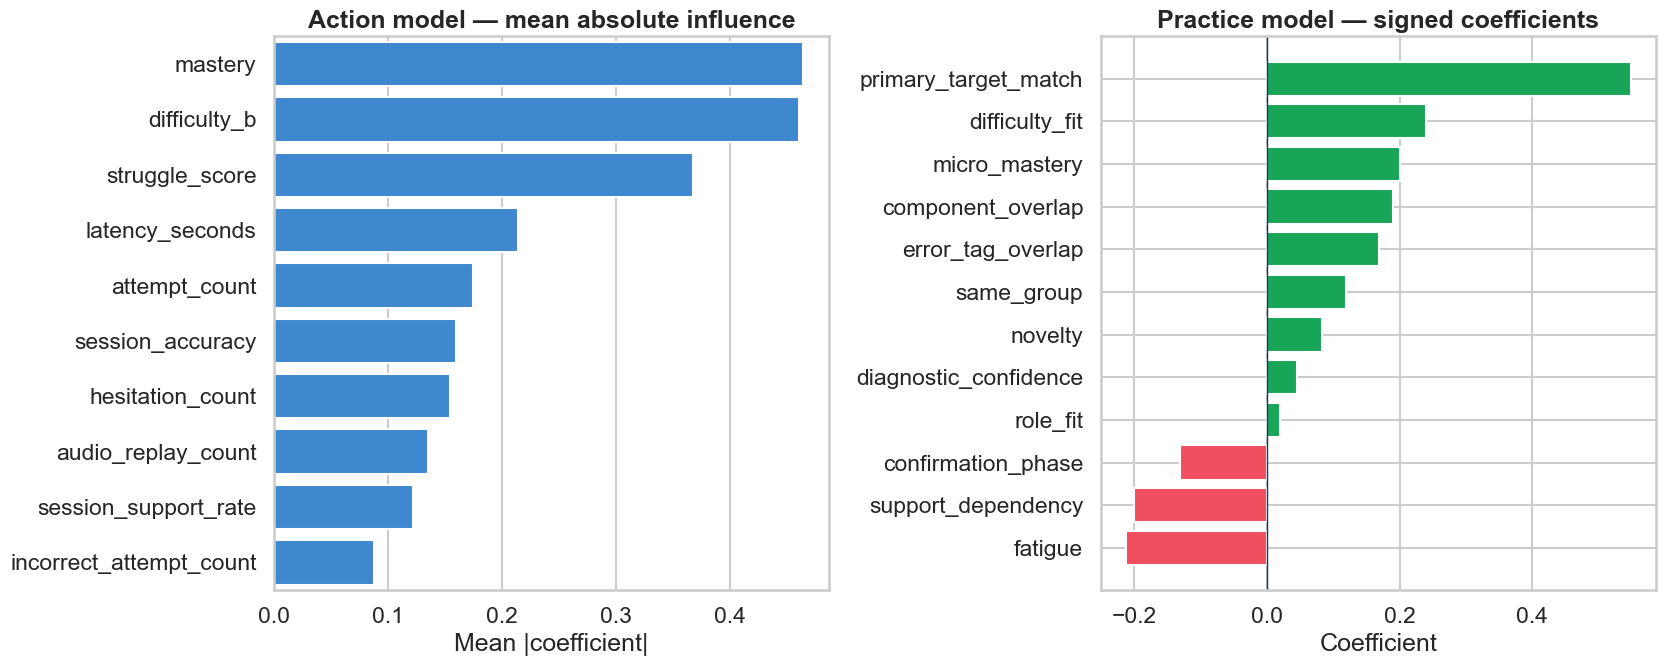

In [7]:
action_weight_rows = []
for action, model in action_artifact['models_by_action'].items():
    for feature, weight in model['weights'].items():
        action_weight_rows.append({'Action': action, 'Feature': feature, 'Weight': weight})
action_weights = pd.DataFrame(action_weight_rows)
action_importance = (action_weights.assign(Abs=lambda frame: frame.Weight.abs())
                     .groupby('Feature', as_index=False)['Abs'].mean()
                     .sort_values('Abs', ascending=False).head(10))
practice_weights = pd.Series(practice_artifact['model']['weights']).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.barplot(data=action_importance, y='Feature', x='Abs', ax=axes[0], color=BLUE)
axes[0].set_title('Action model — mean absolute influence')
axes[0].set_xlabel('Mean |coefficient|')
axes[0].set_ylabel('')
colors = [RED if value < 0 else GREEN for value in practice_weights.values]
axes[1].barh(practice_weights.index, practice_weights.values, color=colors)
axes[1].axvline(0, color=NAVY, linewidth=1)
axes[1].set_title('Practice model — signed coefficients')
axes[1].set_xlabel('Coefficient')
plt.tight_layout()
plt.show()

## 6. Reproduced held-out predictions — confusion, ROC and calibration

The JSON artifacts contain aggregate evidence. The deterministic generators and original seed reproduce test rows here so row-level diagnostic plots can be drawn without saving temporary CSV files.

In [8]:
def sigmoid(value):
    return 1 / (1 + math.exp(-max(-30.0, min(30.0, value))))

def artifact_probability(artifact, features, model):
    z = float(model.get('intercept', 0.0))
    for name in artifact['feature_names']:
        scale = float(artifact['feature_scales'].get(name, 1.0)) or 1.0
        standardized = (float(features[name]) - float(artifact['feature_means'].get(name, 0.0))) / scale
        z += float(model['weights'].get(name, 0.0)) * standardized
    return sigmoid(z)

action_test = action_df.iloc[action_test_idx].copy()
action_probs = np.array([
    artifact_probability(action_artifact, row, action_artifact['models_by_action'][row['action']])
    for row in action_test.to_dict('records')
])
action_labels = action_test['next_independent_success'].to_numpy(int)

practice_test = practice_df.loc[practice_test_mask].copy()
practice_probs = np.array([
    artifact_probability(practice_artifact, row, practice_artifact['model'])
    for row in practice_test.to_dict('records')
])
practice_labels = practice_test['independent_success'].to_numpy(int)

reproduced = pd.DataFrame([
    {'Model': 'Per-action runtime models', 'Accuracy': accuracy_score(action_labels, action_probs >= .5), 'ROC-AUC': roc_auc_score(action_labels, action_probs), 'Brier': brier_score_loss(action_labels, action_probs)},
    {'Model': 'Practice selector', 'Accuracy': accuracy_score(practice_labels, practice_probs >= .5), 'ROC-AUC': roc_auc_score(practice_labels, practice_probs), 'Brier': brier_score_loss(practice_labels, practice_probs)},
])
display(reproduced.style.format({'Accuracy': '{:.2%}', 'ROC-AUC': '{:.3f}', 'Brier': '{:.3f}'}))

,Model,Accuracy,ROC-AUC,Brier
0,Per-action runtime models,88.92%,0.704,0.092
1,Practice selector,80.32%,0.710,0.145


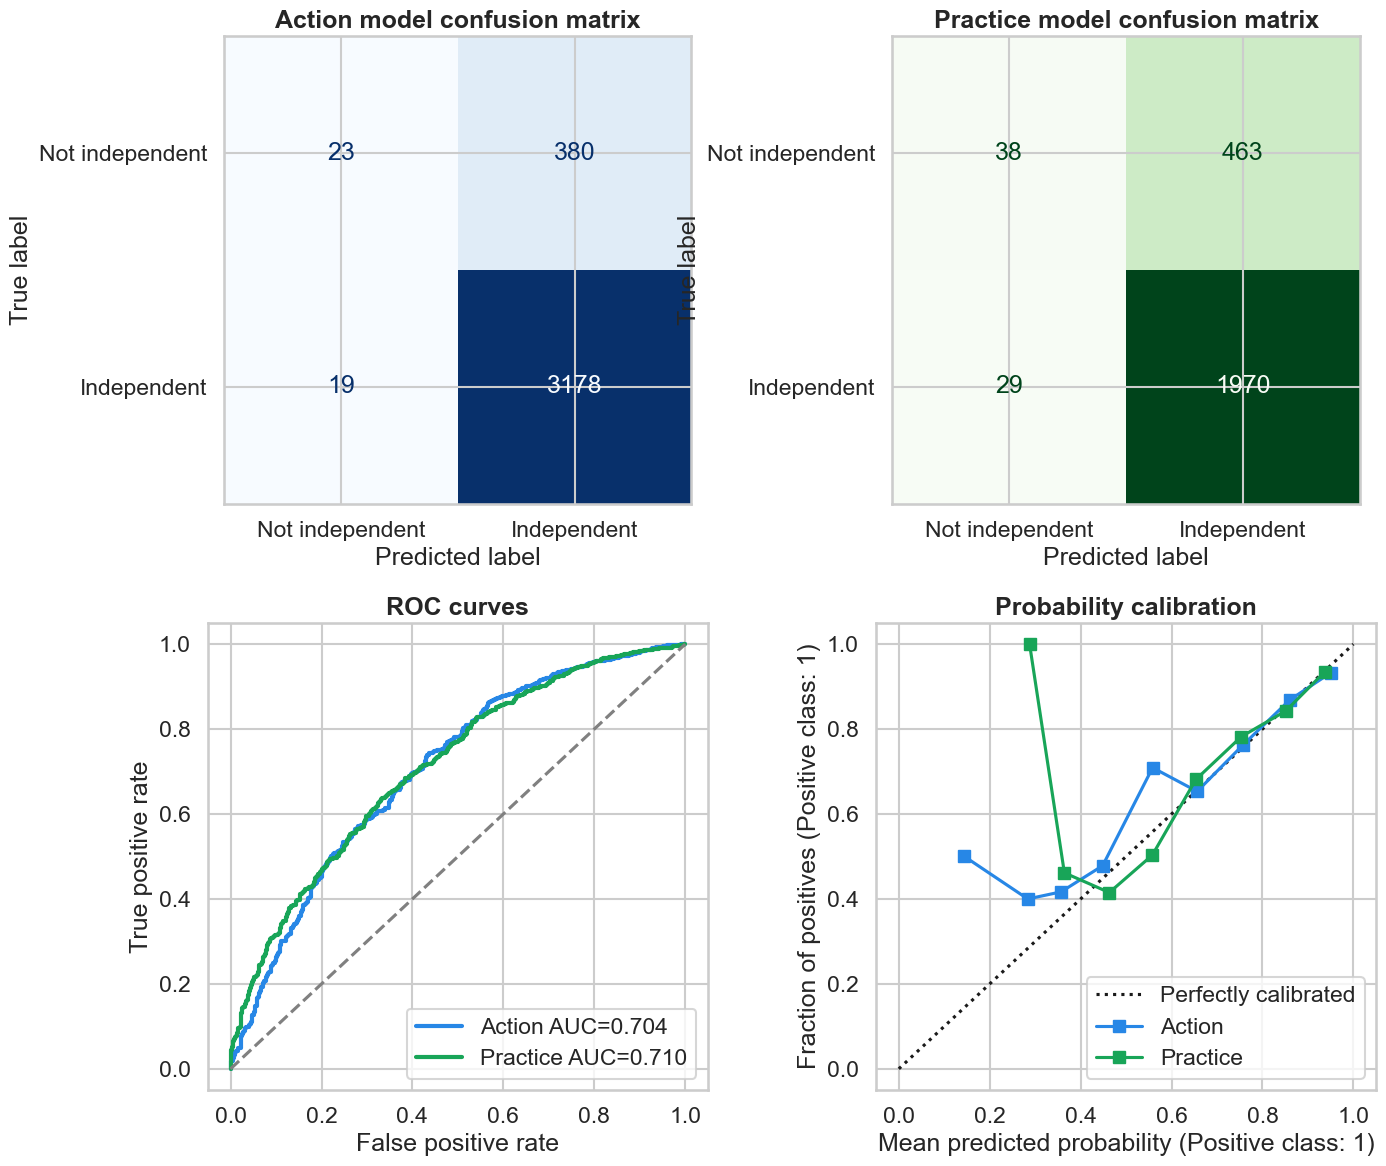

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(action_labels, action_probs >= .5, display_labels=['Not independent', 'Independent'], cmap='Blues', ax=axes[0, 0], colorbar=False)
axes[0, 0].set_title('Action model confusion matrix')
ConfusionMatrixDisplay.from_predictions(practice_labels, practice_probs >= .5, display_labels=['Not independent', 'Independent'], cmap='Greens', ax=axes[0, 1], colorbar=False)
axes[0, 1].set_title('Practice model confusion matrix')
for labels, probabilities, label, color in [(action_labels, action_probs, 'Action', BLUE), (practice_labels, practice_probs, 'Practice', GREEN)]:
    fpr, tpr, _ = roc_curve(labels, probabilities)
    axes[1, 0].plot(fpr, tpr, linewidth=3, label=f'{label} AUC={roc_auc_score(labels, probabilities):.3f}', color=color)
axes[1, 0].plot([0, 1], [0, 1], '--', color='grey')
axes[1, 0].set_title('ROC curves')
axes[1, 0].set_xlabel('False positive rate')
axes[1, 0].set_ylabel('True positive rate')
axes[1, 0].legend()
CalibrationDisplay.from_predictions(action_labels, action_probs, n_bins=10, name='Action', ax=axes[1, 1], color=BLUE)
CalibrationDisplay.from_predictions(practice_labels, practice_probs, n_bins=10, name='Practice', ax=axes[1, 1], color=GREEN)
axes[1, 1].set_title('Probability calibration')
plt.tight_layout()
plt.show()

## 7. BKT mastery trajectory — explanatory example

This is a transparent formula demonstration using the current provisional BKT parameters. Remediation is recorded as intervention response and does not directly raise mastery; core and fresh confirmation provide mastery evidence.

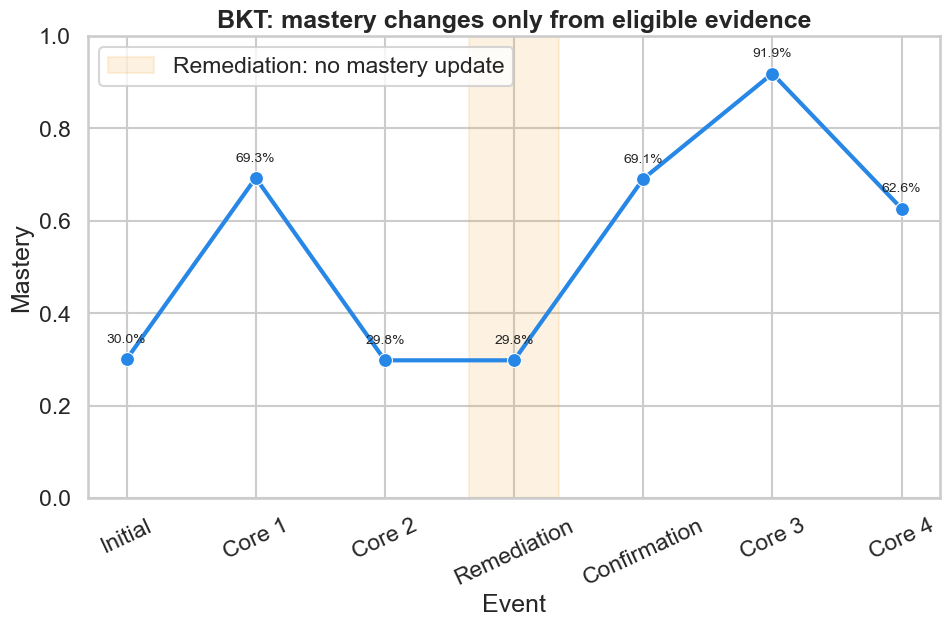

,Event,Mastery,Updated
0,Initial,30.00%,False
1,Core 1,69.27%,True
2,Core 2,29.78%,True
3,Remediation,29.78%,False
4,Confirmation,69.06%,True
5,Core 3,91.85%,True
6,Core 4,62.64%,True


In [10]:
bkt = BKTEngine()
kc = 'KC_VISUAL_PATTERN'
events = [
    ('Core 1', True, True),
    ('Core 2', False, True),
    ('Remediation', True, False),
    ('Confirmation', True, True),
    ('Core 3', True, True),
    ('Core 4', False, True),
]
mastery = bkt.priors[kc][0]
trajectory = [{'Event': 'Initial', 'Mastery': mastery, 'Updated': False}]
for label, correct, update in events:
    if update:
        mastery = bkt.update_knowledge_state(mastery, kc, correct)
    trajectory.append({'Event': label, 'Mastery': mastery, 'Updated': update})
bkt_df = pd.DataFrame(trajectory)
ax = sns.lineplot(data=bkt_df, x='Event', y='Mastery', marker='o', linewidth=3, markersize=10, color=BLUE)
for index, row in bkt_df.iterrows():
    ax.annotate(f"{row['Mastery']:.1%}", (index, row['Mastery']), xytext=(0, 12), textcoords='offset points', ha='center', fontsize=10)
ax.axvspan(2.65, 3.35, color=AMBER, alpha=.15, label='Remediation: no mastery update')
ax.set_ylim(0, 1)
ax.set_title('BKT: mastery changes only from eligible evidence')
ax.tick_params(axis='x', rotation=25)
ax.legend()
plt.show()
display(bkt_df.style.format({'Mastery': '{:.2%}'}))

## 8. Rasch/IRT ability and item difficulty — explanatory example

The item characteristic curves show that the probability of success increases when learner ability $\theta$ becomes higher than item difficulty $b$.

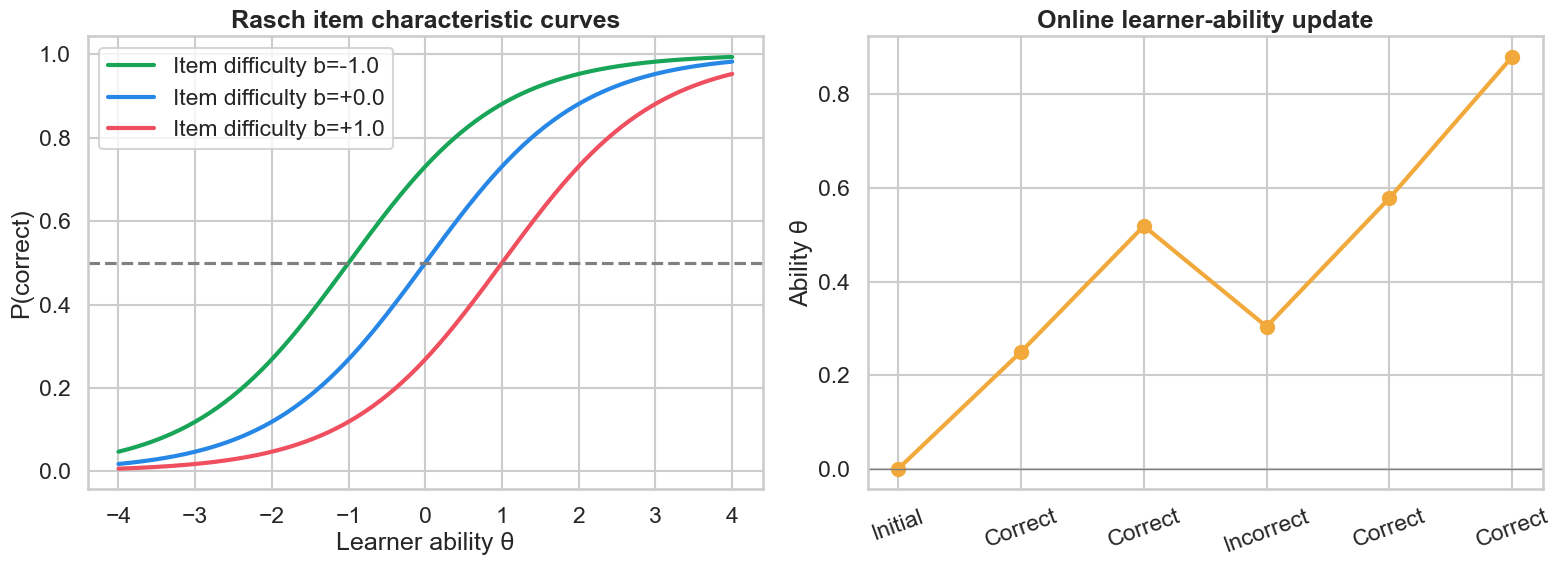

In [11]:
irt = IRTEngine()
theta_values = np.linspace(-4, 4, 250)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for difficulty, color in [(-1.0, GREEN), (0.0, BLUE), (1.0, RED)]:
    probabilities = [irt.calculate_probability(theta, difficulty) for theta in theta_values]
    axes[0].plot(theta_values, probabilities, linewidth=3, color=color, label=f'Item difficulty b={difficulty:+.1f}')
axes[0].axhline(.5, linestyle='--', color='grey')
axes[0].set_title('Rasch item characteristic curves')
axes[0].set_xlabel('Learner ability θ')
axes[0].set_ylabel('P(correct)')
axes[0].legend()

responses = [(0.0, True), (0.4, True), (0.8, False), (0.5, True), (1.0, True)]
theta = 0.0
theta_path = [theta]
for difficulty, correct in responses:
    theta = irt.update_theta(theta, correct, difficulty)
    theta_path.append(theta)
axes[1].plot(range(len(theta_path)), theta_path, marker='o', linewidth=3, markersize=10, color=AMBER)
axes[1].axhline(0, color='grey', linewidth=1)
axes[1].set_xticks(range(len(theta_path)), ['Initial', 'Correct', 'Correct', 'Incorrect', 'Correct', 'Correct'], rotation=20)
axes[1].set_title('Online learner-ability update')
axes[1].set_ylabel('Ability θ')
plt.tight_layout()
plt.show()

## Viva summary

- The scaffold-action Logistic Regression achieved **88.86% held-out accuracy**, **0.708 ROC-AUC**, and **0.092 Brier score** in the saved model comparison.
- The targeted-practice Logistic Regression achieved **80.32% held-out accuracy**, **0.710 ROC-AUC**, and **0.145 Brier score**.
- Evaluation was learner-independent: **75% training learners and 25% unseen testing learners**.
- BKT estimates mastery per knowledge component; Rasch/IRT estimates learner ability relative to item difficulty.
- All reported selector metrics are **synthetic-data functional evidence**, not real-child efficacy evidence.